# Support Vector Machine (SVM)

## 1. What is it?
**SVM** is a **supervised learning** algorithm used for **classification** (and also regression — SVR). It finds the **optimal decision boundary (hyperplane)** that best separates classes by **maximizing the margin** between them.

- Primarily a **binary classifier** (extendable to multi-class)
- Works for **linear** and **non-linear** data (via the kernel trick)
- One of the most powerful classical ML algorithms, especially for high-dimensional data

---

## 2. Intuition
Imagine two groups of points on a plane that you need to separate with a straight line. Many lines could separate them — SVM picks the **one line that stays as far as possible from both groups**, like walking down the middle of the widest possible street between two neighborhoods.

> The "street width" is the **margin**. SVM maximizes it because a wider margin generalizes better to new, unseen points.

---

## 3. Key Terms

| Term | Meaning |
|---|---|
| **Hyperplane** | The decision boundary separating classes ($wx + b = 0$) |
| **Margin** | The distance between the hyperplane and the nearest points of each class |
| **Support Vectors** | The data points closest to the hyperplane — they alone determine its position |
| **Maximum Margin Classifier** | SVM's core idea: choose the hyperplane with the largest margin |

Only the **support vectors** matter — removing any other point doesn't change the boundary at all.

---

## 4. Visual Idea

```
        o   o
      o   o    <-- Class B margin boundary
   ----------------  <-- hyperplane (wx + b = 0)
      x   x    <-- Class A margin boundary
        x   x

   Support vectors = closest o's and x's to the hyperplane
   Margin = distance between the two dashed boundaries
```

---

## 5. Mathematical Formulation

### Hyperplane
$$
w \cdot x + b = 0
$$

### Decision rule
$$
\hat{y} = \text{sign}(w \cdot x + b)
$$

### Margin boundaries
$$
w \cdot x + b = +1 \quad \text{(positive class boundary)}
$$
$$
w \cdot x + b = -1 \quad \text{(negative class boundary)}
$$

### Margin width
$$
\text{Margin} = \frac{2}{\lVert w \rVert}
$$

### Hard-Margin Optimization (perfectly separable data)
Maximize the margin ⇔ minimize $\lVert w \rVert$:

$$
\min_{w,b} \frac{1}{2}\lVert w \rVert^2 \quad \text{subject to } y_i(w \cdot x_i + b) \geq 1 \;\; \forall i
$$

### Soft-Margin Optimization (allows some misclassification)
$$
\min_{w,b,\xi} \frac{1}{2}\lVert w \rVert^2 + C \sum_{i=1}^{n} \xi_i
$$
$$
\text{subject to } y_i(w \cdot x_i + b) \geq 1 - \xi_i, \quad \xi_i \geq 0
$$

Where:
- $\xi_i$ = slack variable (how much point $i$ violates the margin)
- $C$ = regularization parameter controlling the trade-off between margin width and misclassification

---

## 6. The Regularization Parameter C

| C value | Effect |
|---|---|
| **Large C** | Less tolerance for misclassification → narrow margin, risk of **overfitting** |
| **Small C** | More tolerance for misclassification → wider margin, risk of **underfitting** |

> C controls the bias-variance trade-off: it's the penalty for points inside the margin or misclassified.

---

## 7. Non-Linear Data: The Kernel Trick

When data isn't linearly separable, SVM maps it into a **higher-dimensional space** where a linear separator *does* exist — without explicitly computing the transformation (computationally expensive). This is the **kernel trick**:

$$
K(x_i, x_j) = \phi(x_i) \cdot \phi(x_j)
$$

The kernel computes the dot product in the higher-dimensional space directly, using only the original inputs.

### Common Kernels

| Kernel | Formula | Use case |
|---|---|---|
| **Linear** | $K(x_i,x_j) = x_i \cdot x_j$ | Linearly separable, high-dimensional data (e.g., text) |
| **Polynomial** | $K(x_i,x_j) = (\gamma\, x_i \cdot x_j + r)^d$ | Curved boundaries, feature interactions |
| **RBF (Gaussian)** | $K(x_i,x_j) = \exp(-\gamma \lVert x_i - x_j \rVert^2)$ | Default choice; handles complex, non-linear boundaries |
| **Sigmoid** | $K(x_i,x_j) = \tanh(\gamma\, x_i \cdot x_j + r)$ | Behaves like a neural network layer |

### Visual Idea (Kernel Trick)
```
Original space (not separable):      Mapped space (separable):
   x  o  x  o  x                           o
                                         x     x
   (1D, mixed)                       (now a circle separates
                                       x's inside, o's outside)
```

### Gamma (for RBF/poly/sigmoid)

| Gamma value | Effect |
|---|---|
| **Large gamma** | Each point has a small influence radius → tight, wiggly boundary → **overfitting** risk |
| **Small gamma** | Each point has a large influence radius → smoother boundary → **underfitting** risk |

---

## 8. Python Example

```python
import matplotlib.pyplot as plt
import numpy as np
from sklearn.svm import SVC
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# Non-linear data
X, y = make_moons(n_samples=300, noise=0.2, random_state=42)
X = StandardScaler().fit_transform(X)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# RBF kernel SVM
model = SVC(kernel='rbf', C=1.0, gamma='scale')
model.fit(X_train, y_train)

print("Train accuracy:", model.score(X_train, y_train))
print("Test accuracy:", model.score(X_test, y_test))
print("Number of support vectors:", model.n_support_)

# Decision boundary plot
def plot_boundary(model, X, y):
    x_min, x_max = X[:,0].min()-1, X[:,0].max()+1
    y_min, y_max = X[:,1].min()-1, X[:,1].max()+1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                          np.linspace(y_min, y_max, 300))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    plt.contourf(xx, yy, Z, alpha=0.3)
    plt.scatter(X[:,0], X[:,1], c=y, edgecolors='k')
    plt.title('SVM Decision Boundary (RBF kernel)')
    plt.show()

plot_boundary(model, X, y)
```

---

## 9. Key Hyperparameters (scikit-learn `SVC`)

| Parameter | Meaning |
|---|---|
| `C` | Regularization strength (margin vs misclassification trade-off) |
| `kernel` | `'linear'`, `'poly'`, `'rbf'` (default), `'sigmoid'` |
| `gamma` | Kernel coefficient for rbf/poly/sigmoid (`'scale'`, `'auto'`, or a float) |
| `degree` | Degree of the polynomial kernel |
| `class_weight` | Handle class imbalance (`'balanced'` or custom weights) |

**Tuning tip:** use `GridSearchCV` to tune `C` and `gamma` together — they strongly interact.

```python
from sklearn.model_selection import GridSearchCV

param_grid = {'C': [0.1, 1, 10, 100], 'gamma': [1, 0.1, 0.01, 0.001]}
grid = GridSearchCV(SVC(kernel='rbf'), param_grid, cv=5)
grid.fit(X_train, y_train)
print(grid.best_params_)
```

---

## 10. SVM for Regression (SVR)
**Support Vector Regression** fits a function such that errors within a margin $\epsilon$ are ignored (not penalized), and only points outside the **$\epsilon$-tube** contribute to the loss.

```python
from sklearn.svm import SVR
svr = SVR(kernel='rbf', C=1.0, epsilon=0.1)
svr.fit(X_train, y_train)
```

---

## 11. Multi-Class SVM
SVM is inherently binary. Scikit-learn handles multi-class automatically using:
- **One-vs-Rest (OvR):** train K classifiers, each separating one class from the rest
- **One-vs-One (OvO):** train $\binom{K}{2}$ classifiers, one per class pair (used internally by `SVC`)

---

## 12. Complexity
- **Training time:** roughly $O(n^2)$ to $O(n^3)$ depending on implementation — **slow on large datasets**
- **Prediction time:** depends on number of support vectors (fast if few support vectors)
- Works well when **features > samples** (e.g., text classification, genomics)

---

## 13. Advantages
- Effective in **high-dimensional spaces**, even when dimensions > samples
- **Memory efficient** at prediction time (only support vectors matter)
- Versatile via different **kernels**
- Works well with **clear margin of separation**
- Robust to overfitting in high dimensions (with proper C, kernel)

## 14. Limitations
- **Doesn't scale well** to very large datasets (slow training)
- **Sensitive to feature scaling** — must standardize/normalize
- **No direct probability estimates** (needs extra calibration, `probability=True`, which is costly)
- **Choosing the right kernel and hyperparameters (C, gamma)** can be tricky and requires tuning
- Not great with **noisy data / overlapping classes** unless soft margin tuned carefully
- Less interpretable than simpler models (e.g., logistic regression, decision trees)

---

## 15. SVM vs Other Classifiers

| Aspect | SVM | Logistic Regression | Decision Tree |
|---|---|---|---|
| Boundary | Linear or non-linear (kernel) | Linear | Axis-aligned splits |
| Margin-based? | Yes | No | No |
| Probabilistic output | Not natively | Yes | Yes |
| Handles high dimensions | Very well | Well | Can overfit |
| Interpretability | Low (esp. with kernels) | High | High |
| Scalability | Poor for large n | Good | Good |

---

## 16. Applications
- Text and document classification (spam detection, sentiment analysis)
- Image classification (face detection, handwriting recognition)
- Bioinformatics (gene/protein classification)
- Fraud detection
- Any high-dimensional, small-to-medium dataset problem

---

## 17. Common Pitfalls
- **Not scaling features** — SVM is distance/margin based, extremely sensitive to feature scale
- Using **linear kernel on clearly non-linear data**
- Setting **C and gamma without tuning** (grid search is almost mandatory)
- Using SVM on **huge datasets** without considering training time
- Forgetting that **predict_proba** requires `probability=True` (adds computational cost via internal cross-validation)

---

## 18. Quick Revision Points
- **Type:** supervised, margin-based classifier (and regressor via SVR)
- **Goal:** maximize the margin between classes
- **Support vectors:** closest points to the hyperplane; only they matter
- **C:** controls margin width vs misclassification tolerance
- **Kernel trick:** handles non-linear data without explicit transformation
- **Gamma:** controls influence radius of each point (RBF/poly/sigmoid)
- **Always scale features**
- **Multi-class:** via One-vs-Rest or One-vs-One

---

## 19. Likely Exam / Interview Questions
1. **What are support vectors?**
   The data points closest to the hyperplane that determine its position and orientation.
2. **What does the parameter C control?**
   The trade-off between maximizing the margin and minimizing misclassification; large C = narrow margin/low tolerance, small C = wide margin/high tolerance.
3. **What is the kernel trick and why is it useful?**
   It computes dot products in a higher-dimensional space implicitly, allowing non-linear separation without explicitly transforming the data — saving computation.
4. **Difference between hard margin and soft margin SVM?**
   Hard margin requires perfect separation (no errors allowed); soft margin allows some misclassification via slack variables, controlled by C.
5. **How does gamma affect the RBF kernel?**
   Large gamma → tight, wiggly boundary (overfitting risk); small gamma → smooth boundary (underfitting risk).
6. **Why is feature scaling important for SVM?**
   Because it relies on distances/dot products — unscaled features with larger ranges dominate the margin calculation.
7. **Is SVM sensitive to outliers?**
   Yes, especially with hard margin or large C, since outliers can become support vectors and distort the boundary.

---

Want the next note on **Logistic Regression**, **Decision Trees**, or **Naive Bayes**?

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.svm import SVC
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [2]:
# Non-linear data
X, y = make_moons(n_samples=300, noise=0.2, random_state=42)
X = StandardScaler().fit_transform(X)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [3]:
# RBF kernel SVM
model = SVC(kernel='rbf', C=1.0, gamma='scale')
model.fit(X_train, y_train)

print("Train accuracy:", model.score(X_train, y_train))
print("Test accuracy:", model.score(X_test, y_test))
print("Number of support vectors:", model.n_support_)

Train accuracy: 0.9333333333333333
Test accuracy: 0.9333333333333333
Number of support vectors: [35 35]


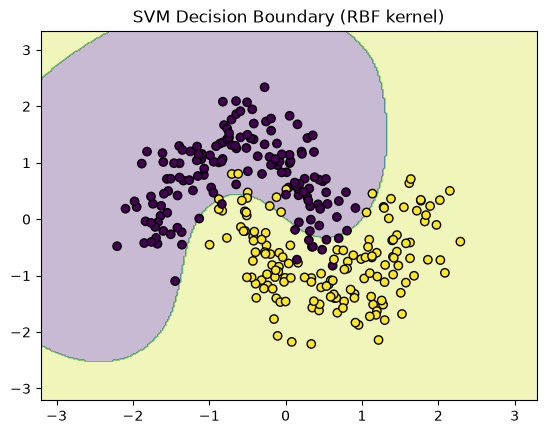

In [4]:
# Decision boundary plot
def plot_boundary(model, X, y):
    x_min, x_max = X[:,0].min()-1, X[:,0].max()+1
    y_min, y_max = X[:,1].min()-1, X[:,1].max()+1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                          np.linspace(y_min, y_max, 300))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    plt.contourf(xx, yy, Z, alpha=0.3)
    plt.scatter(X[:,0], X[:,1], c=y, edgecolors='k')
    plt.title('SVM Decision Boundary (RBF kernel)')
    plt.show()

plot_boundary(model, X, y)

In [5]:
import pandas as pd
from sklearn.datasets import load_iris

In [6]:
iris = load_iris()

In [7]:
iris

{'data': array([[5.1, 3.5, 1.4, 0.2],
        [4.9, 3. , 1.4, 0.2],
        [4.7, 3.2, 1.3, 0.2],
        [4.6, 3.1, 1.5, 0.2],
        [5. , 3.6, 1.4, 0.2],
        [5.4, 3.9, 1.7, 0.4],
        [4.6, 3.4, 1.4, 0.3],
        [5. , 3.4, 1.5, 0.2],
        [4.4, 2.9, 1.4, 0.2],
        [4.9, 3.1, 1.5, 0.1],
        [5.4, 3.7, 1.5, 0.2],
        [4.8, 3.4, 1.6, 0.2],
        [4.8, 3. , 1.4, 0.1],
        [4.3, 3. , 1.1, 0.1],
        [5.8, 4. , 1.2, 0.2],
        [5.7, 4.4, 1.5, 0.4],
        [5.4, 3.9, 1.3, 0.4],
        [5.1, 3.5, 1.4, 0.3],
        [5.7, 3.8, 1.7, 0.3],
        [5.1, 3.8, 1.5, 0.3],
        [5.4, 3.4, 1.7, 0.2],
        [5.1, 3.7, 1.5, 0.4],
        [4.6, 3.6, 1. , 0.2],
        [5.1, 3.3, 1.7, 0.5],
        [4.8, 3.4, 1.9, 0.2],
        [5. , 3. , 1.6, 0.2],
        [5. , 3.4, 1.6, 0.4],
        [5.2, 3.5, 1.5, 0.2],
        [5.2, 3.4, 1.4, 0.2],
        [4.7, 3.2, 1.6, 0.2],
        [4.8, 3.1, 1.6, 0.2],
        [5.4, 3.4, 1.5, 0.4],
        [5.2, 4.1, 1.5, 0.1],
  

In [8]:
x = pd.DataFrame(iris.data, columns = iris.feature_names)

In [9]:
x

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


In [10]:
y = pd.DataFrame(iris.target, columns = ["Target"])

In [11]:
y

,Target
0,0
1,0
2,0
3,0
4,0
...,...
145,2
146,2
147,2
148,2


In [15]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

# Load Iris data
iris = load_iris()

df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

df["species"] = pd.Categorical.from_codes(
    iris.target,
    iris.target_names
)

print(df.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  


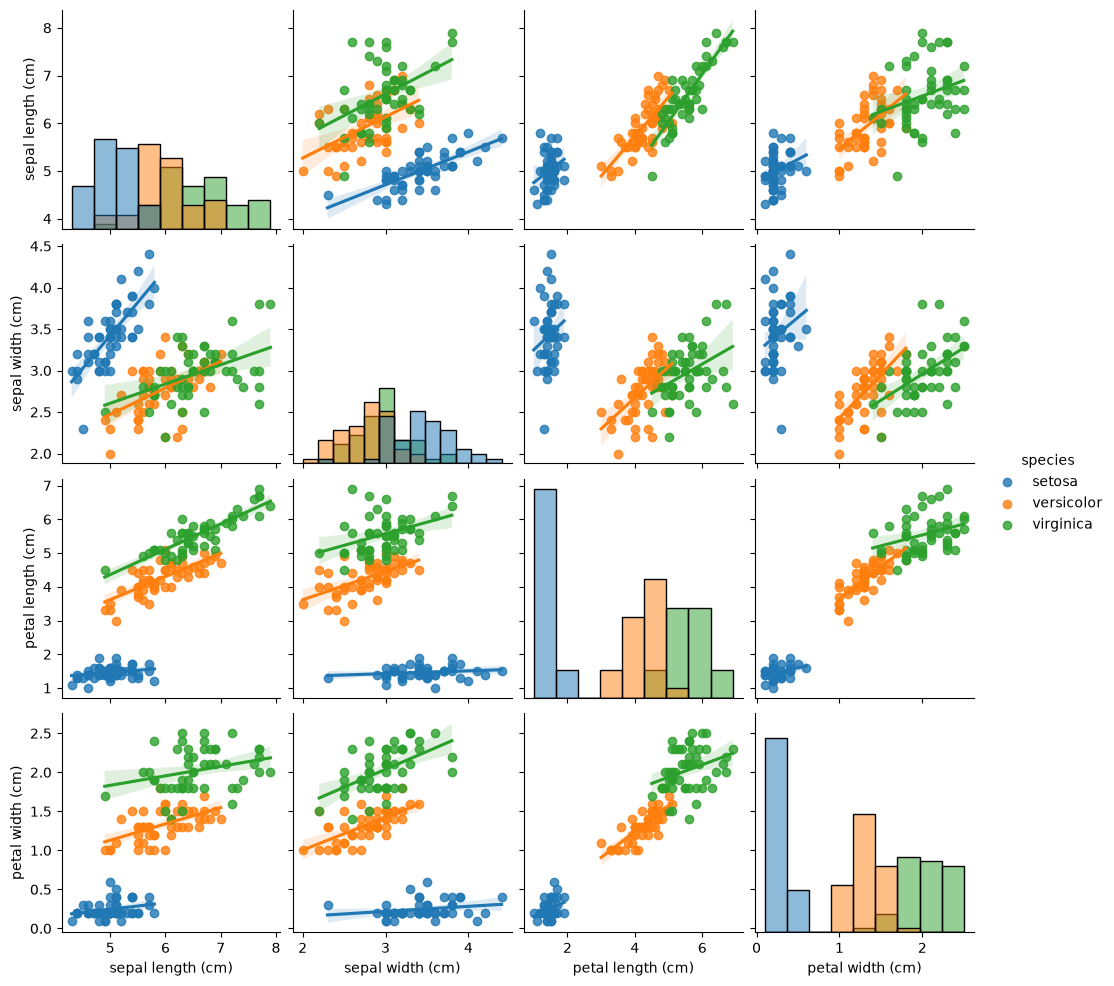

In [16]:
sns.pairplot(
    df,
    hue="species",
    kind="reg",
    diag_kind="hist"
)

plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

xtrain, xtest, ytrain, ytest = train_test_split(x, y, test_size=0.2, random_state=42)

In [ ]:
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()

xtrain_sc = sc.fit_transform(xtrain)
xtest_sc = sc.transform(xtest)

In [ ]:
from sklearn.svm import SVC

model = SVC(
    kernel = "rbf",
    C = 10,
    gamma = "scale"
)

In [ ]:
model.fit(xtrain_sc, ytrain)

In [ ]:
y_pred = model.predict(xtest_sc)

In [ ]:
y_pred

In [ ]:
ytest

In [ ]:
from sklearn.metrics import accuracy_score

accuracy_score(ytest, y_pred)

In [ ]:
ytest["predict"] = y_pred

In [ ]:
ytest